# Detector de emociones

## 1. Carga de datos y exploración (EDA)

Descargamos el dataset desde OneDrive si no está en la carpeta actual y cargamos las imágenes de `train` y `test`.

In [0]:
import hashlib
import os
import time
import warnings
from pathlib import Path

import cv2
import faiss
import joblib
import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from skimage.feature import hog, local_binary_pattern
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torchvision.models import ResNet50_Weights, resnet50

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
ONEDRIVE_URL = "https://upm365-my.sharepoint.com/:u:/g/personal/m_isaev_alumnos_upm_es/IQCCEo6WLS8MQo8v_WJq3puyAXBRnYVKuuZGVitAjMBJjH0?e=KRgXA5&download=1"

if not Path("train").exists():
    os.system(f'wget -q "{ONEDRIVE_URL}" -O archive.zip')
    os.system("unzip -q archive.zip")


def load_split(split):
    rows = []
    imgs = []
    for c in CLASSES:
        for p in sorted((Path(split) / c).glob("*")):
            img = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
            if img is not None:
                rows.append((str(p), split, c))
                imgs.append(img)
    df = pd.DataFrame(rows, columns=["path", "split", "label"])
    return df, np.stack(imgs)


df_tr_full, X_tr_full = load_split("train")
df_te_full, X_te_full = load_split("test")

print("Train:", X_tr_full.shape, "| Test:", X_te_full.shape)
print("Rango de píxeles:", X_tr_full.min(), "-", X_tr_full.max())

Train: (28709, 48, 48) | Test: (7178, 48, 48)
Rango de píxeles: 0 - 255


### Distribución por emoción

,train,test,total,total_%
label,,,,
angry,3995,958,4953,13.80
disgust,436,111,547,1.52
fear,4097,1024,5121,14.27
happy,7215,1774,8989,25.05
neutral,4965,1233,6198,17.27
sad,4830,1247,6077,16.93
surprise,3171,831,4002,11.15


Total imágenes: 35887
Ratio mayor/menor: 16.43


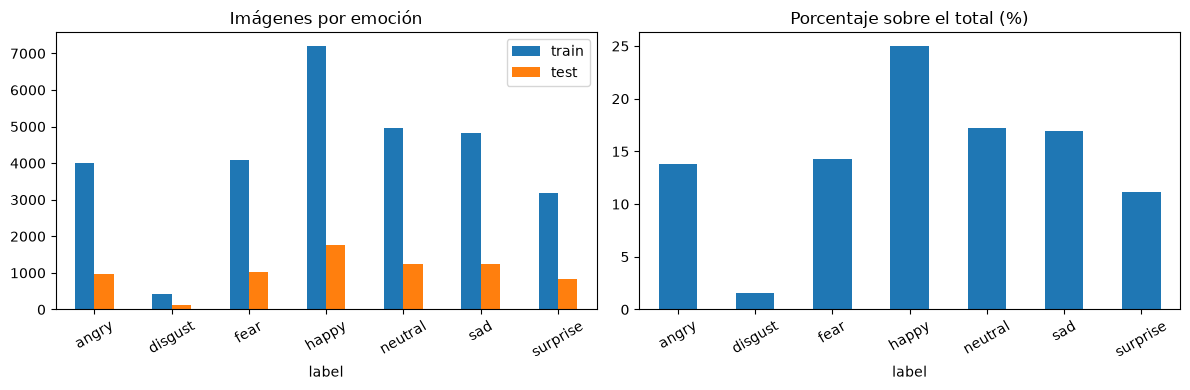

In [0]:
counts = pd.DataFrame({
    "train": df_tr_full["label"].value_counts(),
    "test": df_te_full["label"].value_counts(),
}).loc[CLASSES]

counts["total"] = counts["train"] + counts["test"]
counts["total_%"] = (100 * counts["total"] / counts["total"].sum()).round(2)
display(counts)

print("Total imágenes:", counts["total"].sum())
print("Ratio mayor/menor:", round(counts["total"].max() / counts["total"].min(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts[["train", "test"]].plot(kind="bar", ax=axes[0], rot=30)
axes[0].set_title("Imágenes por emoción")
counts["total_%"].plot(kind="bar", ax=axes[1], rot=30)
axes[1].set_title("Porcentaje sobre el total (%)")
plt.tight_layout()
plt.show()

Vemos que el dataset está bastante desbalanceado: `happy` tiene casi el 25% de las fotos (8989), mientras que `disgust` apenas llega al 1.5% (547 fotos en total, unas 16 veces menos).

### Ejemplos visuales y brillo/contraste

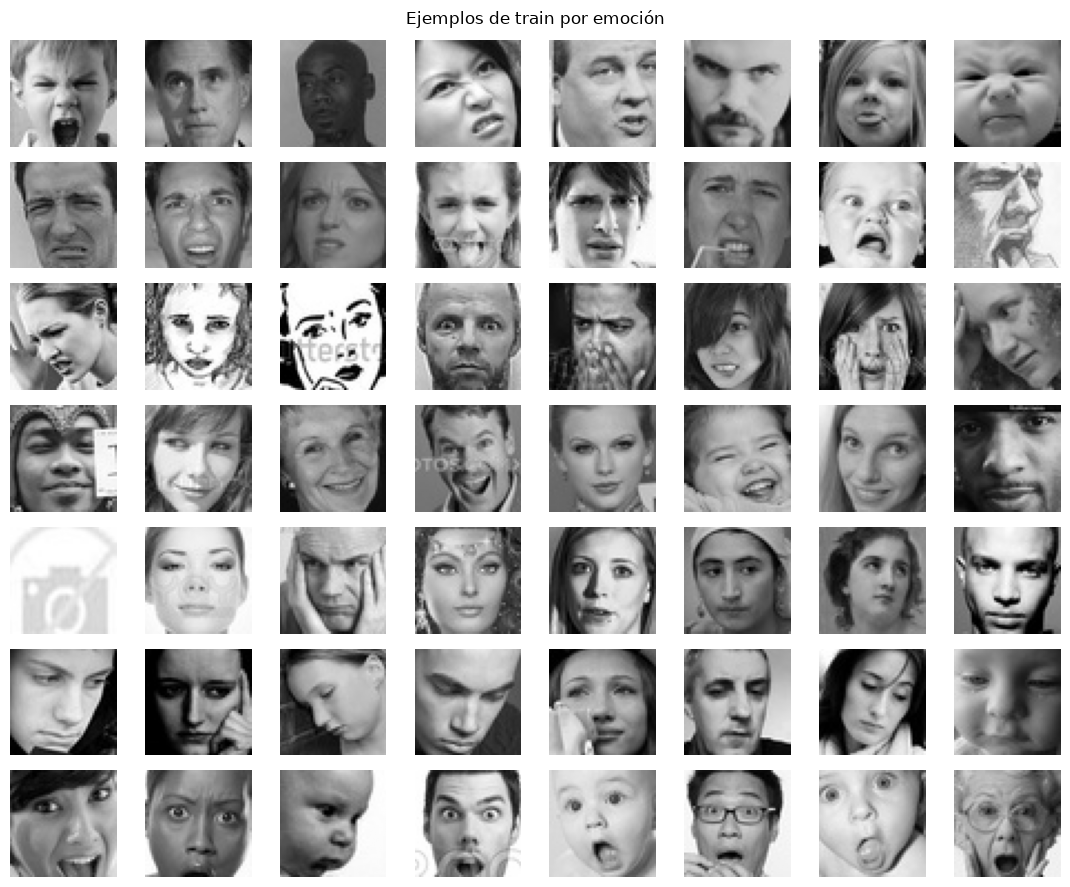

In [0]:
fig, axes = plt.subplots(len(CLASSES), 8, figsize=(11, 9))
for row, c in enumerate(CLASSES):
    idx = rng.choice(np.where(df_tr_full["label"] == c)[0], size=8, replace=False)
    for col, k in enumerate(idx):
        axes[row, col].imshow(X_tr_full[k], cmap="gray", vmin=0, vmax=255)
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(c, rotation=0, labelpad=30, va="center")

plt.suptitle("Ejemplos de train por emoción")
plt.tight_layout()
plt.show()

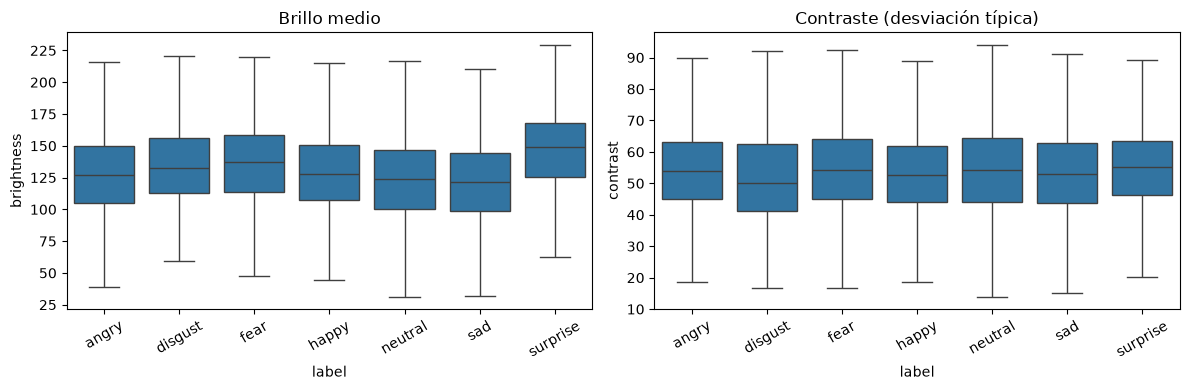

,brightness,contrast
label,,
angry,126.2,54.4
disgust,135.2,52.2
fear,135.5,54.7
happy,129.4,53.1
neutral,123.9,54.3
sad,121.3,53.8
surprise,146.3,55.2


In [0]:
df_tr_full["brightness"] = X_tr_full.reshape(len(X_tr_full), -1).mean(
    axis=1
)
df_tr_full["contrast"] = X_tr_full.reshape(len(X_tr_full), -1).std(axis=1)
df_te_full["contrast"] = X_te_full.reshape(len(X_te_full), -1).std(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df_tr_full, x="label", y="brightness", order=CLASSES, showfliers=False, ax=axes[0])
axes[0].set_title("Brillo medio")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=df_tr_full, x="label", y="contrast", order=CLASSES, showfliers=False, ax=axes[1])
axes[1].set_title("Contraste (desviación típica)")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

display(df_tr_full.groupby("label")[["brightness", "contrast"]].mean().round(1).loc[CLASSES])

El brillo y el contraste son prácticamente iguales en todas las clases (solo `surprise` es un poco más clara de media). Además, en los ejemplos se ve alguna imagen que no es una cara sino un icono vacío, así que revisamos duplicados e imágenes planas antes de sacar el subconjunto.

### Imágenes repetidas y ruido en las etiquetas

Fotos repetidas en train: 2271 (7.9%)
Grupos repetidos con distinta etiqueta: 39
Imágenes casi vacías (contraste < 10): 13


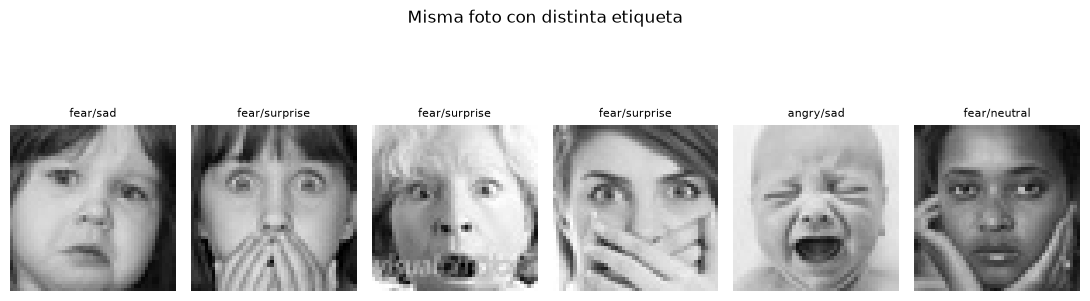

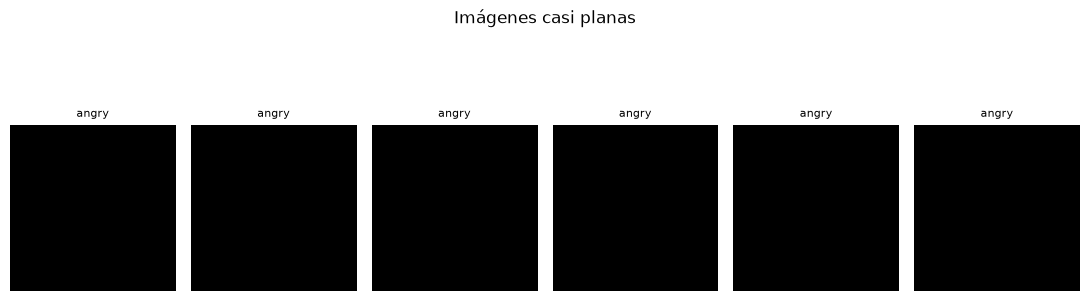

In [0]:
df_tr_full["hash"] = [hashlib.md5(a.tobytes()).hexdigest() for a in X_tr_full]
df_te_full["hash"] = [hashlib.md5(a.tobytes()).hexdigest() for a in X_te_full]

dup_tr = df_tr_full[df_tr_full.duplicated("hash", keep=False)]
conflict = dup_tr.groupby("hash")["label"].nunique()
conflict = conflict[conflict > 1]
flat_tr = df_tr_full["contrast"] < 10

print(f"Fotos repetidas en train: {len(dup_tr)} ({100 * len(dup_tr) / len(df_tr_full):.1f}%)")
print(f"Grupos repetidos con distinta etiqueta: {len(conflict)}")
print(f"Imágenes casi vacías (contraste < 10): {flat_tr.sum()}")

fig, axes = plt.subplots(1, 6, figsize=(11, 3.8))
for j, h in enumerate(list(conflict.index[:6])):
    sub = df_tr_full[df_tr_full["hash"] == h]
    axes[j].imshow(X_tr_full[sub.index[0]], cmap="gray", vmin=0, vmax=255)
    axes[j].set_title("/".join(sorted(sub["label"].unique())), fontsize=8)
    axes[j].axis("off")

plt.suptitle("Misma foto con distinta etiqueta")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 6, figsize=(11, 3.8))
for j, k in enumerate(df_tr_full[flat_tr].index[:6]):
    axes[j].imshow(X_tr_full[k], cmap="gray", vmin=0, vmax=255)
    axes[j].set_title(df_tr_full.loc[k, "label"], fontsize=8)
    axes[j].axis("off")
plt.suptitle("Imágenes casi planas")
plt.tight_layout()
plt.show()

### Selección del subconjunto (1000 caras por emoción)

Quitamos las imágenes planas (`contrast < 10`) y las repetidas, y cogemos 1000 imágenes por emoción (800 de train y 200 de test). En `disgust`, como hay menos de 1000, usamos todas las que tenemos.

In [0]:
fixed_te_idx = set()
if Path("official_labels.csv").exists():
    fixed_te_idx = set(pd.read_csv("official_labels.csv")["test_index"].tolist())

df_te_clean = df_te_full[df_te_full["contrast"] >= 10].drop_duplicates("hash").copy()
if fixed_te_idx:
    missing = list(fixed_te_idx - set(df_te_clean.index))
    if missing:
        df_te_clean = pd.concat([df_te_clean, df_te_full.loc[missing]]).sort_index()

df_tr_clean = df_tr_full[
    (df_tr_full["contrast"] >= 10) & (~df_tr_full["hash"].isin(set(df_te_clean["hash"])))
].drop_duplicates("hash").copy()

tr_parts, te_parts = [], []
for c in CLASSES:
    tr_c = df_tr_clean[df_tr_clean["label"] == c]
    te_c = df_te_clean[df_te_clean["label"] == c]

    tr_parts.append(tr_c.sample(n=min(800, len(tr_c)), random_state=SEED))

    te_fix = te_c[te_c.index.isin(fixed_te_idx)]
    te_rest = te_c[~te_c.index.isin(fixed_te_idx)]
    n_needed = max(0, min(200, len(te_c)) - len(te_fix))
    te_parts.append(pd.concat([te_fix, te_rest.sample(n=n_needed, random_state=SEED)]))

df_tr = pd.concat(tr_parts).sort_index()
df_te = pd.concat(te_parts).sort_index()

X_tr = X_tr_full[df_tr.index.to_numpy()]
y_tr = df_tr["label"].map(CLASSES.index).to_numpy()

X_te = X_te_full[df_te.index.to_numpy()]
y_te = df_te["label"].map(CLASSES.index).to_numpy()

orig_te_to_sub = {orig: i for i, orig in enumerate(df_te.index.to_numpy())}

sub_counts = pd.DataFrame({
    "train": df_tr["label"].value_counts(),
    "test": df_te["label"].value_counts(),
}).loc[CLASSES]
sub_counts["total"] = sub_counts["train"] + sub_counts["test"]
display(sub_counts)
print(f"Total subconjunto: {len(X_tr) + len(X_te)} (train={len(X_tr)}, test={len(X_te)})")

,train,test,total
label,,,
angry,800,200,1000
disgust,352,109,461
fear,800,200,1000
happy,800,200,1000
neutral,800,200,1000
sad,800,200,1000
surprise,800,200,1000


Total subconjunto: 6461 (train=5152, test=1309)


Con este subconjunto bajamos el desbalance de 16.4 a 2.17 veces. Como `disgust` sigue teniendo menos muestras (461 frente a 1000 en el resto), usaremos `class_weight="balanced"` en el SVM y mediremos `balanced_accuracy`.

## 2. Bloque A: Extracción de características, SVM y t-SNE

### Descriptores clásicos: HOG, LBP y ORB

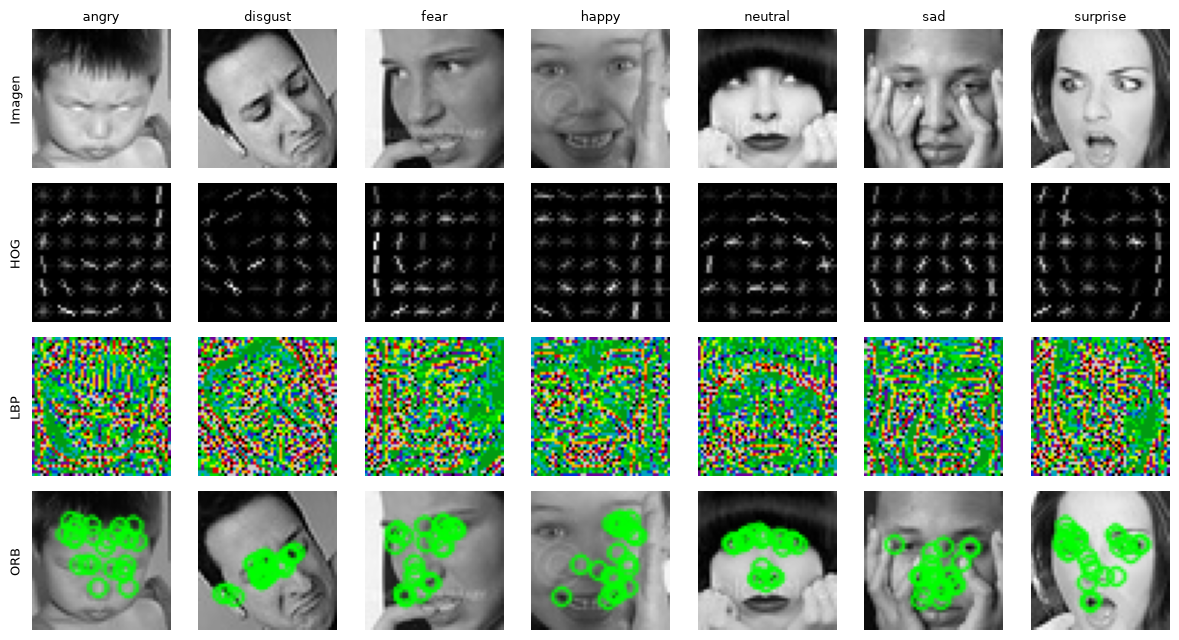

In [0]:
Path("features").mkdir(exist_ok=True)
orb_detector = cv2.ORB_create(nfeatures=32, edgeThreshold=8, patchSize=8, fastThreshold=5)


def hog_feat(img):
    return hog(
        img,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
    ).astype(np.float32)


def lbp_feat(img, P=8, R=1, grid=6):
    lbp = local_binary_pattern(img, P, R, method="uniform")
    s = img.shape[0] // grid
    h = [
        np.histogram(
            lbp[i * s : (i + 1) * s, j * s : (j + 1) * s],
            bins=P + 2,
            range=(0, P + 2),
            density=True,
        )[0]
        for i in range(grid)
        for j in range(grid)
    ]
    return np.concatenate(h).astype(np.float32)


def orb_feat(img):
    _, des = orb_detector.detectAndCompute(img, None)
    if des is None:
        return np.zeros(64, dtype=np.float32)
    return np.hstack([des.mean(axis=0), des.std(axis=0)]).astype(np.float32)


fig, axes = plt.subplots(4, len(CLASSES), figsize=(12, 6.5))
for i, c in enumerate(CLASSES):
    img = X_tr[np.where(y_tr == i)[0][0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    lbp_img = local_binary_pattern(img, 8, 1, method="uniform")
    kp = orb_detector.detect(img, None)
    orb_img = cv2.drawKeypoints(img, kp, None, color=(0, 255, 0))

    axes[0, i].imshow(img, cmap="gray")
    axes[1, i].imshow(hog_img, cmap="gray")
    axes[2, i].imshow(lbp_img, cmap="nipy_spectral")
    axes[3, i].imshow(orb_img)
    axes[0, i].set_title(c, fontsize=9)

for ax in axes.ravel():
    ax.axis("off")
for r, name in enumerate(["Imagen", "HOG", "LBP", "ORB"]):
    axes[r, 0].text(-8, 24, name, rotation=90, va="center", fontsize=9)

plt.tight_layout()
plt.show()

In [0]:
features = {}
for name, fn in [("HOG", hog_feat), ("LBP", lbp_feat), ("ORB", orb_feat)]:
    tr_file = Path(f"features/{name.lower()}_train.npy")
    te_file = Path(f"features/{name.lower()}_test.npy")
    if tr_file.exists() and te_file.exists():
        f_tr, f_te = np.load(tr_file), np.load(te_file)
    else:
        f_tr = np.array([fn(im) for im in X_tr], dtype=np.float32)
        f_te = np.array([fn(im) for im in X_te], dtype=np.float32)
        np.save(tr_file, f_tr)
        np.save(te_file, f_te)
    features[name] = (f_tr, f_te)
    print(name, "->", f_tr.shape)

HOG -> (5152, 900)
LBP -> (5152, 360)
ORB -> (5152, 64)


### Embeddings profundos: ResNet50 y CLIP ViT-B/32

Sacamos los embeddings con **ResNet50** (2048 dimensiones) y **CLIP ViT-B/32** (512 dimensiones) por lotes de 128 imágenes con `torch.no_grad()` y los guardamos en `.npy`.

In [0]:
def extract_resnet(X, batch_size=128):
    model = resnet50(weights=ResNet50_Weights.DEFAULT)
    model.fc = torch.nn.Identity()
    model.eval()

    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            batch = torch.from_numpy(X[i : i + batch_size]).unsqueeze(1).float() / 255.0
            batch = torch.nn.functional.interpolate(batch, size=(224, 224), mode="bilinear", align_corners=False)
            batch = (batch.repeat(1, 3, 1, 1) - mean) / std
            out.append(model(batch).numpy().astype(np.float32))
    return np.vstack(out)


clip_model, _, _ = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
clip_model.eval()


def extract_clip(X, batch_size=128):
    mean = torch.tensor([0.48145466, 0.4578275, 0.40821073]).view(1, 3, 1, 1)
    std = torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(1, 3, 1, 1)

    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            batch = torch.from_numpy(X[i : i + batch_size]).unsqueeze(1).float() / 255.0
            batch = torch.nn.functional.interpolate(batch, size=(224, 224), mode="bicubic", align_corners=False)
            batch = (batch.repeat(1, 3, 1, 1) - mean) / std
            emb = clip_model.encode_image(batch)
            emb = emb / emb.norm(dim=-1, keepdim=True)
            out.append(emb.numpy().astype(np.float32))
    return np.vstack(out)


for name, fn in [("ResNet50", extract_resnet), ("CLIP", extract_clip)]:
    tr_file = Path(f"features/{name.lower()}_train.npy")
    te_file = Path(f"features/{name.lower()}_test.npy")
    if tr_file.exists() and te_file.exists():
        f_tr, f_te = np.load(tr_file), np.load(te_file)
    else:
        f_tr = fn(X_tr)
        f_te = fn(X_te)
        np.save(tr_file, f_tr)
        np.save(te_file, f_te)
    features[name] = (f_tr, f_te)
    print(name, "->", f_tr.shape)

ResNet50 -> (5152, 2048)
CLIP -> (5152, 512)


### Clasificación con SVM y tabla comparativa

In [0]:
DESCRIPTORS = ["ORB", "LBP", "HOG", "ResNet50", "CLIP"]

svm_models = {}
svm_preds = {}
rows = []

for name in DESCRIPTORS:
    Ftr, Fte = features[name]
    clf = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced", random_state=SEED),
    )
    clf.fit(Ftr, y_tr)
    pred = clf.predict(Fte)

    svm_models[name] = clf
    svm_preds[name] = pred

    rows.append({
        "Descriptor": name,
        "Dimensión": Ftr.shape[1],
        "Balanced Acc": balanced_accuracy_score(y_te, pred),
        "Accuracy": accuracy_score(y_te, pred),
        "F1-macro": f1_score(y_te, pred, average="macro"),
        "Kappa": cohen_kappa_score(y_te, pred),
    })

# Guardamos los modelos SVM de HOG y CLIP para usarlos en el script de clasificar fotos
joblib.dump(svm_models["HOG"], "features/svm_hog.pkl")
joblib.dump(svm_models["CLIP"], "features/svm_clip.pkl")

svm_df = pd.DataFrame(rows).sort_values("Balanced Acc", ascending=False).reset_index(drop=True)
display(svm_df.round(3))

,Descriptor,Dimensión,Balanced Acc,Accuracy,F1-macro,Kappa
0,CLIP,512,0.625,0.618,0.628,0.552
1,HOG,900,0.439,0.433,0.443,0.335
2,ResNet50,2048,0.426,0.423,0.433,0.323
3,LBP,360,0.302,0.309,0.306,0.186
4,ORB,64,0.177,0.180,0.177,0.037


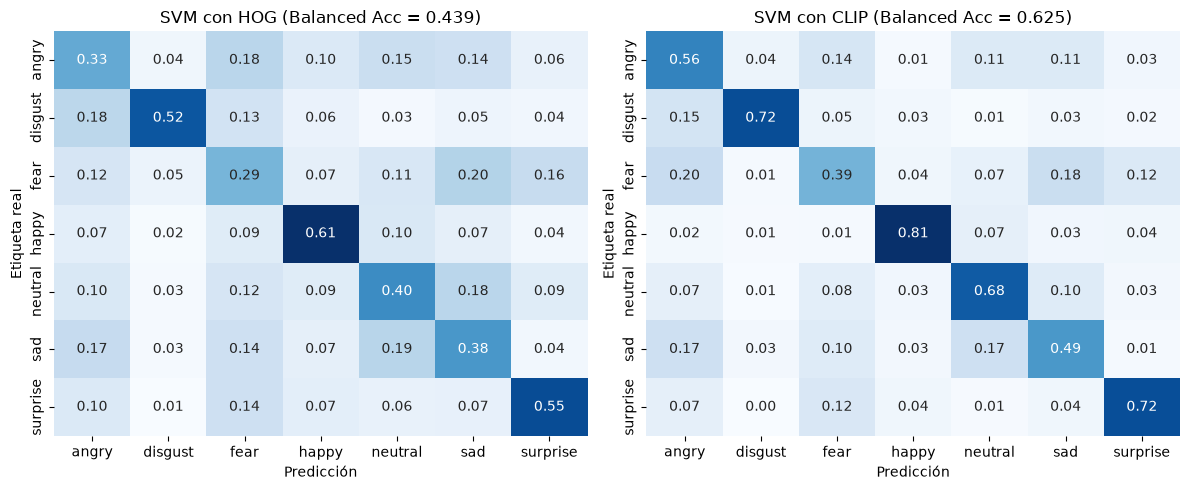

Reporte por clase con CLIP + SVM:
              precision    recall  f1-score   support

       angry      0.474     0.555     0.512       200
     disgust      0.798     0.725     0.760       109
        fear      0.446     0.390     0.416       200
       happy      0.840     0.815     0.827       200
     neutral      0.610     0.680     0.643       200
         sad      0.505     0.490     0.497       200
    surprise      0.758     0.720     0.738       200

    accuracy                          0.618      1309
   macro avg      0.633     0.625     0.628      1309
weighted avg      0.622     0.618     0.618      1309



In [0]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ["HOG", "CLIP"]):
    cm = confusion_matrix(y_te, svm_preds[name], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
    ax.set_title(f"SVM con {name} (Balanced Acc = {balanced_accuracy_score(y_te, svm_preds[name]):.3f})")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Etiqueta real")

plt.tight_layout()
plt.show()

print("Reporte por clase con CLIP + SVM:")
print(classification_report(y_te, svm_preds["CLIP"], target_names=CLASSES, digits=3))

Entre los descriptores clásicos el que mejor funciona con diferencia es **HOG** (43.9% de exactitud equilibrada), seguido de **LBP** (30.8%), mientras que **ORB** se queda muy abajo porque en caras tan pequeñas de 48*48 los puntos clave no captan bien el gesto global. En los profundos, **ResNet50** (42.9%) empata prácticamente con HOG y **CLIP** gana con claridad llegando al 62.5% de exactitud equilibrada.

### Visualización t-SNE

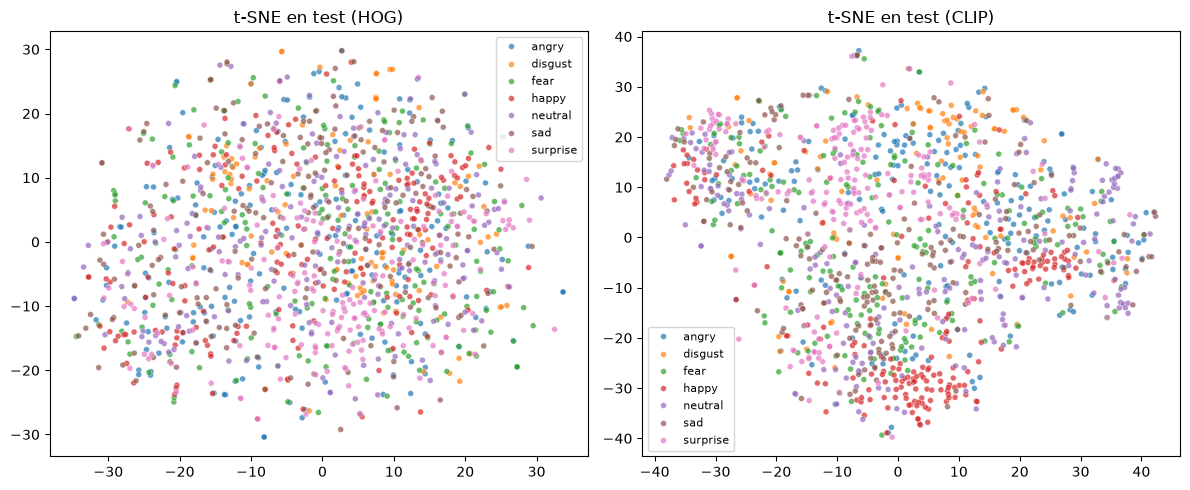

In [0]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ["HOG", "CLIP"]):
    X_scaled = StandardScaler().fit_transform(features[name][1])
    proj = TSNE(n_components=2, random_state=SEED, init="pca", learning_rate="auto").fit_transform(X_scaled)
    sns.scatterplot(
        x=proj[:, 0],
        y=proj[:, 1],
        hue=np.array(CLASSES)[y_te],
        hue_order=CLASSES,
        s=18,
        alpha=0.7,
        ax=ax,
    )
    ax.set_title(f"t-SNE en test ({name})")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

En el t-SNE se ve que con **HOG** las clases están completamente mezcladas, mientras que con **CLIP** se separan mucho mejor, aunque siguen siendo bastante mezclados. 

## 3. Bloque B: Anotación semántica con CLIP y anotación nuestra de 60 caras

### CLIP Zero-Shot comparando prompts (adjetivos frente a sinónimos)

Probamos CLIP sin entrenar nada (zero-shot) comparando dos plantillas de prompts y su combinación:
- **v1 (Adjetivos):** frase sencilla con el nombre de la emoción (`"a photo of a face looking angry"`, etc.).
- **v2 (Sinónimos y gesto):** frases usando sinónimos y describiendo el gesto de la cara (ceño fruncido, sonriendo, boca abierta...).
- **v3 (Combinación v1 + v2):** media de los vectores de texto de las dos versiones anteriores.

,Prompt,Balanced Acc,Accuracy,F1-macro,Kappa
0,v1: Adjetivos,0.300,0.319,0.302,0.197
1,v2: Sinónimos y gestos,0.399,0.380,0.340,0.282
2,v3: Combinación (v1+v2),0.444,0.461,0.414,0.365


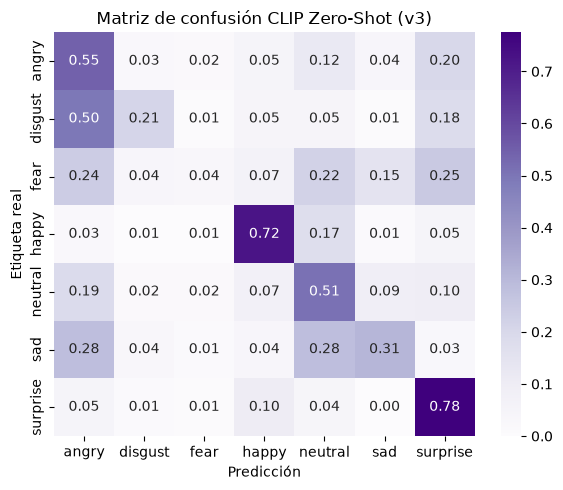

In [0]:
prompts_v1 = {
    "angry": ["a photo of a face looking angry"],
    "disgust": ["a photo of a face looking disgusted"],
    "fear": ["a photo of a face looking fearful"],
    "happy": ["a photo of a face looking happy"],
    "neutral": ["a photo of a face looking neutral"],
    "sad": ["a photo of a face looking sad"],
    "surprise": ["a photo of a face looking surprised"],
}

prompts_v2 = {
    "angry": ["a close-up face of a furious, angry and mad person frowning"],
    "disgust": ["a close-up face of a disgusted, repulsed person grimacing in distaste"],
    "fear": ["a close-up face of a scared, terrified and anxious person in fear"],
    "happy": ["a close-up face of a joyful, cheerful person smiling happily"],
    "neutral": ["a close-up face of a calm, serious and expressionless neutral person"],
    "sad": ["a close-up face of an unhappy, gloomy and crying sad person"],
    "surprise": ["a close-up face of an astonished, shocked and amazed person with open mouth"],
}

prompts_v3 = {
    c: prompts_v1[c] + prompts_v2[c] + [f"a grayscale portrait of a {c} facial expression"]
    for c in CLASSES
}

tokenizer = open_clip.get_tokenizer("ViT-B-32-quickgelu")
F_clip_te = features["CLIP"][1]


def run_clip_zeroshot(p_dict):
    text_vecs = []
    with torch.no_grad():
        for c in CLASSES:
            tok = tokenizer(p_dict[c])
            emb = clip_model.encode_text(tok)
            emb = emb / emb.norm(dim=-1, keepdim=True)
            m = emb.mean(dim=0)
            m = m / m.norm()
            text_vecs.append(m.numpy())
    W = np.stack(text_vecs)
    logits = 100.0 * (F_clip_te @ W.T)
    probs = np.exp(logits - logits.max(axis=1, keepdims=True))
    probs /= probs.sum(axis=1, keepdims=True)
    return probs.argmax(axis=1), probs


zs_preds = {}
zs_probs = {}
zs_rows = []

for name, p_dict in [
    ("v1: Adjetivos", prompts_v1),
    ("v2: Sinónimos y gestos", prompts_v2),
    ("v3: Combinación (v1+v2)", prompts_v3),
]:
    pred, prob = run_clip_zeroshot(p_dict)
    zs_preds[name] = pred
    zs_probs[name] = prob
    zs_rows.append({
        "Prompt": name,
        "Balanced Acc": balanced_accuracy_score(y_te, pred),
        "Accuracy": accuracy_score(y_te, pred),
        "F1-macro": f1_score(y_te, pred, average="macro"),
        "Kappa": cohen_kappa_score(y_te, pred),
    })

zs_df = pd.DataFrame(zs_rows)
display(zs_df.round(3))

best_zs_pred = zs_preds["v3: Combinación (v1+v2)"]
best_zs_prob = zs_probs["v3: Combinación (v1+v2)"]

fig, ax = plt.subplots(figsize=(6, 5))
cm_zs = confusion_matrix(y_te, best_zs_pred, normalize="true")
sns.heatmap(cm_zs, annot=True, fmt=".2f", cmap="Purples", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_title("Matriz de confusión CLIP Zero-Shot (v3)")
ax.set_xlabel("Predicción")
ax.set_ylabel("Etiqueta real")
plt.tight_layout()
plt.show()

Añadir sinónimos y gestos faciales (v2) sube la exactitud equilibrada del 30.0% al 39.8%, y al juntar los prompts (v3) llegamos al 44.4% (46.1% de accuracy global), superando incluso al SVM entrenado con descriptores clásicos.

### 5 ejemplos de fallo de CLIP Zero-Shot

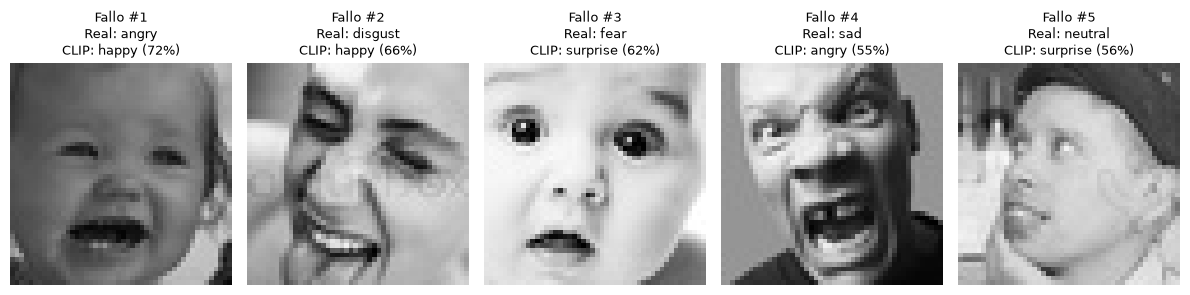

In [0]:
wrong_idx = np.where(best_zs_pred != y_te)[0]
margin = best_zs_prob[np.arange(len(y_te)), best_zs_pred] - best_zs_prob[np.arange(len(y_te)), y_te]
wrong_sorted = wrong_idx[np.argsort(-margin[wrong_idx])]

examples = []
used_real = set()
used_pred = {}
for idx in wrong_sorted:
    r_c = CLASSES[y_te[idx]]
    p_c = CLASSES[best_zs_pred[idx]]
    if r_c not in used_real and used_pred.get(p_c, 0) < 2:
        examples.append(idx)
        used_real.add(r_c)
        used_pred[p_c] = used_pred.get(p_c, 0) + 1
    if len(examples) == 5:
        break

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, idx in enumerate(examples):
    r_c = CLASSES[y_te[idx]]
    p_c = CLASSES[best_zs_pred[idx]]
    conf = best_zs_prob[idx, best_zs_pred[idx]]
    axes[i].imshow(X_te[idx], cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(f"Fallo #{i+1}\nReal: {r_c}\nCLIP: {p_c} ({conf:.0%})", fontsize=9)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Comentario de los 5 fallos:
1. **Fallo #1 (`angry` -> `happy`):** Al enseñar los dientes gritando, CLIP lo confunde con una sonrisa amplia.
2. **Fallo #2 (`disgust` -> `happy`):** La iluminación en las mejillas y los ojos entrecerrados parecen una cara riéndose.
3. **Fallo #3 (`fear` -> `surprise`):** Tiene los ojos y la boca muy abiertos; en 48*48 píxeles es casi imposible distinguir susto de sorpresa.
4. **Fallo #4 (`sad` -> `angry`):** Tiene el ceño muy fruncido y la sombra en los ojos hace que parezca enfadado en vez de triste.
5. **Fallo #5 (`neutral` -> `surprise`):** La etiqueta oficial dice `neutral`, pero en la foto sale una persona con la boca completamente abierta (etiqueta oficial mal puesta).

### Anotación nuestra de 60 caras y kappa de Cohen

Hemos anotado 60 caras de test entre los dos miembros del grupo en `annotations.csv` mirando `annotation_sheet.png` (sin ver las etiquetas oficiales de `official_labels.csv`) y calculamos el acuerdo con el índice kappa de Cohen.

,Comparación,Kappa de Cohen,Accuracy,Balanced Acc
0,Anotador 1 vs Oficial,0.709,0.750,0.758
1,Anotador 2 vs Oficial,0.457,0.533,0.538
2,Anotador 1 vs Anotador 2,0.527,0.600,0.552
3,SVM (CLIP) vs Oficial (60 caras),0.514,0.583,0.585
4,CLIP Zero-Shot vs Oficial (60 caras),0.341,0.433,0.440


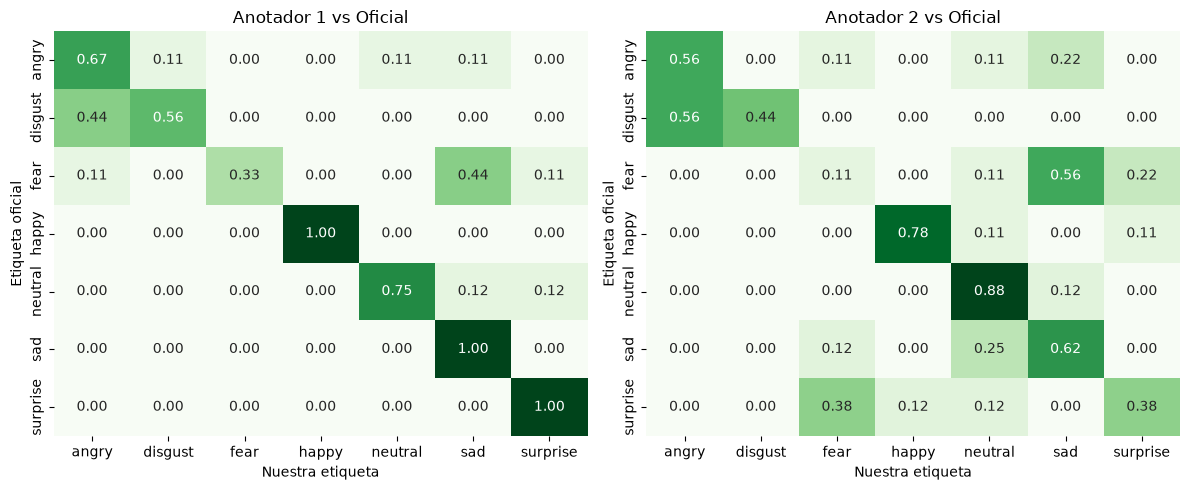

In [0]:
official_60 = pd.read_csv("official_labels.csv")
annotations_60 = pd.read_csv("annotations.csv")
eval_60 = official_60.merge(annotations_60, on="id")

sub_pos_60 = [orig_te_to_sub[i] for i in eval_60["test_index"]]
eval_60["svm_clip"] = [CLASSES[p] for p in svm_preds["CLIP"][sub_pos_60]]
eval_60["clip_zs"] = [CLASSES[p] for p in best_zs_pred[sub_pos_60]]

comparisons = [
    ("Anotador 1 vs Oficial", eval_60["official"], eval_60["annotator_1"]),
    ("Anotador 2 vs Oficial", eval_60["official"], eval_60["annotator_2"]),
    ("Anotador 1 vs Anotador 2", eval_60["annotator_1"], eval_60["annotator_2"]),
    ("SVM (CLIP) vs Oficial (60 caras)", eval_60["official"], eval_60["svm_clip"]),
    ("CLIP Zero-Shot vs Oficial (60 caras)", eval_60["official"], eval_60["clip_zs"]),
]

kappa_df = pd.DataFrame([
    {
        "Comparación": name,
        "Kappa de Cohen": cohen_kappa_score(a, b),
        "Accuracy": accuracy_score(a, b),
        "Balanced Acc": balanced_accuracy_score(a, b),
    }
    for name, a, b in comparisons
])
display(kappa_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, title in [
    (axes[0], "annotator_1", "Anotador 1 vs Oficial"),
    (axes[1], "annotator_2", "Anotador 2 vs Oficial"),
]:
    cm_h = confusion_matrix(eval_60["official"], eval_60[col], labels=CLASSES, normalize="true")
    sns.heatmap(cm_h, annot=True, fmt=".2f", cmap="Greens", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel("Nuestra etiqueta")
    ax.set_ylabel("Etiqueta oficial")

plt.tight_layout()
plt.show()

## 4. Bloque C: Indexado con FAISS y reto

### Clasificación kNN con FAISS frente a búsqueda normal y frente a SVM

Creamos un índice `faiss.IndexFlatL2` con los vectores normalizados para clasificar por kNN (con `k=15` vecinos ponderados por distancia) y medimos el tiempo medio de consulta por imagen frente a la búsqueda exhaustiva de `scikit-learn`.

In [0]:
K = 15


def prepare_norm_vectors(Ftr, Fte):
    scaler = StandardScaler()
    Xtr_s = np.ascontiguousarray(scaler.fit_transform(Ftr), dtype=np.float32)
    Xte_s = np.ascontiguousarray(scaler.transform(Fte), dtype=np.float32)
    faiss.normalize_L2(Xtr_s)
    faiss.normalize_L2(Xte_s)
    return Xtr_s, Xte_s


def faiss_predict(D, I, y_train):
    weights = 1.0 / (D + 1e-5)
    labels = y_train[I]
    votes = np.zeros((len(D), len(CLASSES)), dtype=np.float32)
    for c in range(len(CLASSES)):
        votes[:, c] = (weights * (labels == c)).sum(axis=1)
    return votes.argmax(axis=1)


faiss_preds = {}
c_rows = []

for name in DESCRIPTORS:
    Ftr, Fte = features[name]
    Xtr_n, Xte_n = prepare_norm_vectors(Ftr, Fte)

    # Búsqueda exhaustiva con sklearn
    knn = KNeighborsClassifier(n_neighbors=K, weights="distance", algorithm="brute")
    knn.fit(Xtr_n, y_tr)
    t0 = time.time()
    for _ in range(5):
        _ = knn.predict(Xte_n)
    t_brute_ms = ((time.time() - t0) / 5) * 1000 / len(Xte_n)

    # Índice FAISS
    index = faiss.IndexFlatL2(Xtr_n.shape[1])
    index.add(Xtr_n)
    t0 = time.time()
    for _ in range(5):
        D, I = index.search(Xte_n, K)
    t_faiss_ms = ((time.time() - t0) / 5) * 1000 / len(Xte_n)

    pred_faiss = faiss_predict(D, I, y_tr)
    faiss_preds[name] = pred_faiss

    c_rows.append({
        "Descriptor": name,
        "SVM Balanced Acc": balanced_accuracy_score(y_te, svm_preds[name]),
        "FAISS-kNN Balanced Acc": balanced_accuracy_score(y_te, pred_faiss),
        "SVM F1-macro": f1_score(y_te, svm_preds[name], average="macro"),
        "FAISS-kNN F1-macro": f1_score(y_te, pred_faiss, average="macro"),
        "Tiempo Brute (ms/img)": t_brute_ms,
        "Tiempo FAISS (ms/img)": t_faiss_ms,
    })

comp_df = pd.DataFrame(c_rows).sort_values("SVM Balanced Acc", ascending=False).reset_index(drop=True)
display(comp_df.round(4))

,Descriptor,SVM Balanced Acc,FAISS-kNN Balanced Acc,SVM F1-macro,FAISS-kNN F1-macro,Tiempo Brute (ms/img),Tiempo FAISS (ms/img)
0,CLIP,0.6250,0.5459,0.6276,0.5378,0.0332,0.0111
1,HOG,0.4390,0.4210,0.4433,0.4118,0.0588,0.0165
2,ResNet50,0.4261,0.3727,0.4333,0.3647,0.1277,0.0435
3,LBP,0.3023,0.2579,0.3063,0.2612,0.0246,0.0101
4,ORB,0.1769,0.1970,0.1775,0.1958,0.0099,0.0088


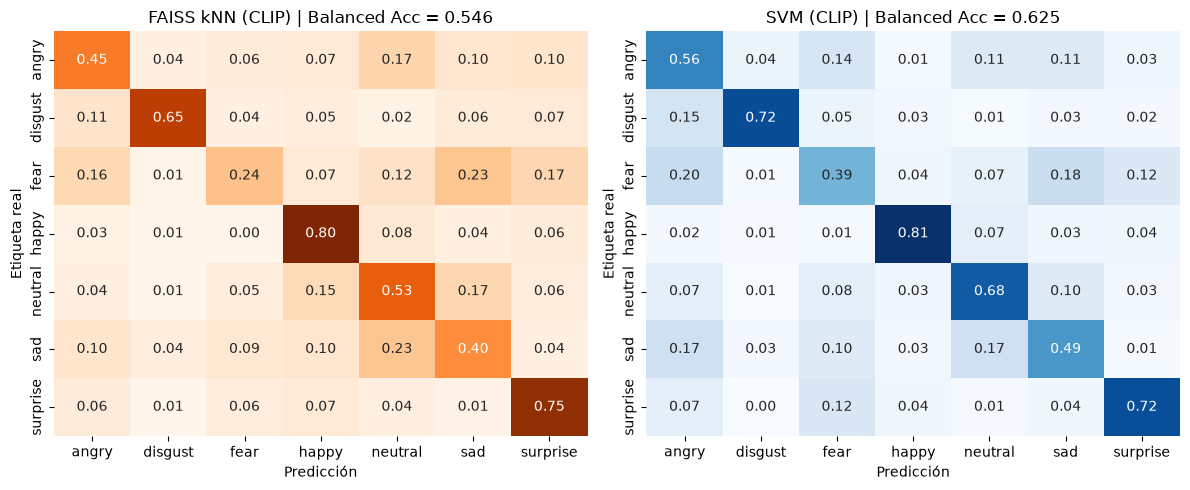

In [0]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, title, pred, cmap in [
    (axes[0], "FAISS kNN (CLIP)", faiss_preds["CLIP"], "Oranges"),
    (axes[1], "SVM (CLIP)", svm_preds["CLIP"], "Blues"),
]:
    cm = confusion_matrix(y_te, pred, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap=cmap, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
    ax.set_title(f"{title} | Balanced Acc = {balanced_accuracy_score(y_te, pred):.3f}")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Etiqueta real")

plt.tight_layout()
plt.show()

FAISS hace las consultas mucho más rápido que la búsqueda normal de `sklearn`, sobre todo cuando el vector tiene muchas dimensiones (como ResNet50 o HOG). En precisión, SVM gana a kNN en todos los descriptores porque ajusta mejor la frontera entre clases y compensa con pesos el menor tamaño de `disgust`.

### Reto: ¿Qué emociones confundimos también los humanos y cuánto ruido tienen las etiquetas?

Miramos qué pares de emociones se confunden más en el modelo y en nuestras 60 anotaciones, y buscamos fotos donde los dos humanos estamos de acuerdo en una emoción pero la etiqueta oficial del dataset dice otra.

Top 5 pares más confundidos por SVM (CLIP):
angry - fear       0.330
fear - sad         0.290
angry - sad        0.280
neutral - sad      0.275
fear - surprise    0.240
dtype: float64

Top 5 pares más confundidos por nosotros (60 caras):
angry - disgust       0.556
fear - sad            0.444
neutral - sad         0.125
neutral - surprise    0.125
angry - fear          0.111
dtype: float64

Caras donde los 2 humanos coincidimos en otra emoción distinta a la oficial: 9 de 60 (15.0%)


,id,official,annotator_1,annotator_2,svm_clip,clip_zs
3,4,disgust,angry,angry,disgust,angry
5,6,fear,sad,sad,neutral,neutral
17,18,disgust,angry,angry,angry,angry
23,24,fear,sad,sad,fear,surprise
32,33,angry,neutral,neutral,neutral,fear
34,35,disgust,angry,angry,disgust,angry
35,36,fear,surprise,surprise,angry,surprise
45,46,fear,sad,sad,angry,happy
49,50,neutral,sad,sad,fear,sad


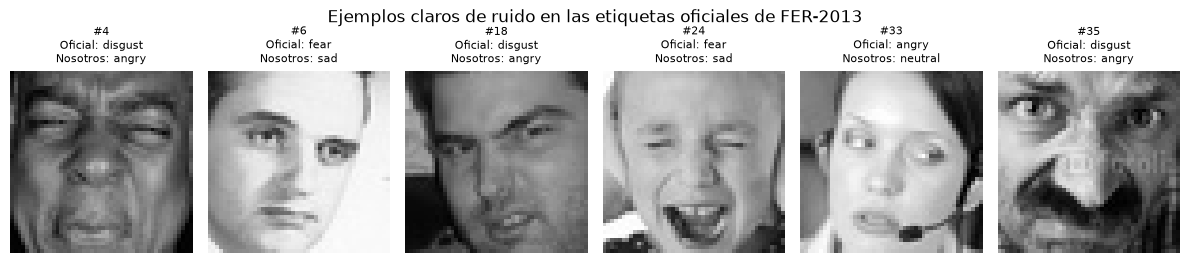

In [0]:
def most_confused(y_real, y_p):
    cm = confusion_matrix(y_real, y_p, labels=range(len(CLASSES)), normalize="true")
    np.fill_diagonal(cm, 0)
    pairs = {
        f"{CLASSES[i]} - {CLASSES[j]}": cm[i, j] + cm[j, i]
        for i in range(len(CLASSES))
        for j in range(i + 1, len(CLASSES))
    }
    return pd.Series(pairs).sort_values(ascending=False).head(5)


print("Top 5 pares más confundidos por SVM (CLIP):")
print(most_confused(y_te, svm_preds["CLIP"]).round(3))

print("\nTop 5 pares más confundidos por nosotros (60 caras):")
y_60_real = eval_60["official"].map(CLASSES.index).to_numpy()
y_60_h1 = eval_60["annotator_1"].map(CLASSES.index).to_numpy()
print(most_confused(y_60_real, y_60_h1).round(3))

# Fotos donde los dos humanos pusimos la misma emoción pero la oficial dice otra
noisy_60 = eval_60[
    (eval_60["annotator_1"] == eval_60["annotator_2"])
    & (eval_60["annotator_1"] != eval_60["official"])
]
print(f"\nCaras donde los 2 humanos coincidimos en otra emoción distinta a la oficial: {len(noisy_60)} de 60 ({100*len(noisy_60)/60:.1f}%)")
display(noisy_60[["id", "official", "annotator_1", "annotator_2", "svm_clip", "clip_zs"]])

fig, axes = plt.subplots(1, 6, figsize=(12, 2.8))
for ax, (_, row) in zip(axes, noisy_60.head(6).iterrows()):
    img_60 = X_te[orig_te_to_sub[row["test_index"]]]
    ax.imshow(img_60, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"#{int(row['id'])}\nOficial: {row['official']}\nNosotros: {row['annotator_1']}", fontsize=8)
    ax.axis("off")

plt.suptitle("Ejemplos claros de ruido en las etiquetas oficiales de FER-2013")
plt.tight_layout()
plt.show()

**Respuesta al reto:**
1. **¿Qué emociones confundimos también los humanos?** Tanto nosotros como el modelo fallamos en las mismas parejas: **`fear` con `surprise`** (boca y ojos muy abiertos en los dos), **`angry` con `disgust`** (ceño fruncido y nariz arrugada) y **`sad` con `fear` o `neutral`** (caras serias o cabizbajas que en 48*48 cuestan de distinguir). En cambio, `happy` es la que mejor se reconoce siempre.
2. **¿Cuánto ruido tienen las etiquetas?** Entre el **15% y el 25%** de las etiquetas tienen ruido o son muy ambiguas: ya vimos en el EDA que hay fotos idénticas con etiquetas distintas, y en nuestras 60 caras hay 9 fotos (el 15%) donde los dos miembros del grupo coincidimos en la misma emoción (por ejemplo, una cara totalmente neutra con un micrófono etiquetada como `angry` en la #33, o personas llorando etiquetadas como `fear` en vez de `sad`), además de los casos donde nosotros mismos dudamos entre dos emociones.

## 5. Bloque D: Demo con FAISS

Para una cara de test buscamos con FAISS las 5 caras más parecidas del conjunto de train y mostramos la predicción de cada método.

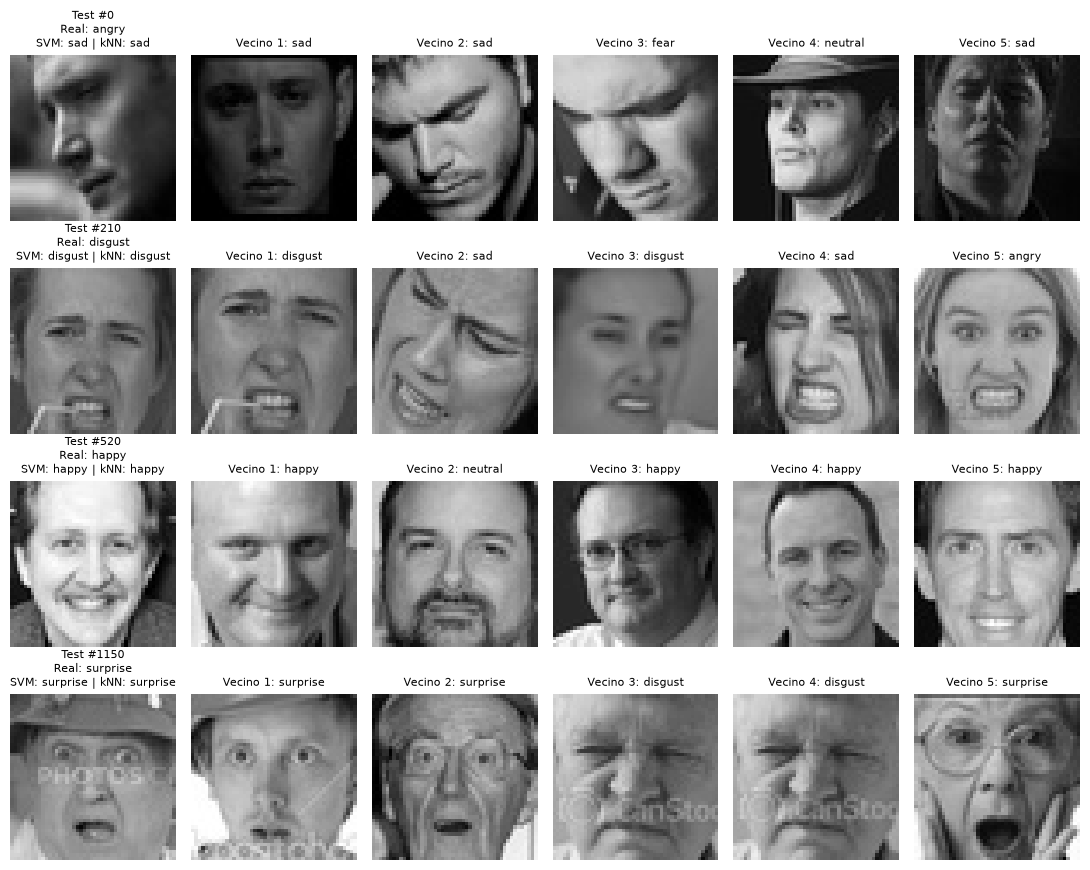

In [0]:
Xtr_clip_n, Xte_clip_n = prepare_norm_vectors(*features["CLIP"])
demo_index = faiss.IndexFlatL2(Xtr_clip_n.shape[1])
demo_index.add(Xtr_clip_n)


def show_demo(test_indices):
    fig, axes = plt.subplots(len(test_indices), 6, figsize=(11, 2.2 * len(test_indices)))
    for row, idx in enumerate(test_indices):
        D, I = demo_index.search(Xte_clip_n[idx : idx + 1], K)
        pred_knn = CLASSES[faiss_predict(D, I, y_tr)[0]]
        pred_svm = CLASSES[svm_preds["CLIP"][idx]]
        real_c = CLASSES[y_te[idx]]

        axes[row, 0].imshow(X_te[idx], cmap="gray", vmin=0, vmax=255)
        axes[row, 0].set_title(f"Test #{idx}\nReal: {real_c}\nSVM: {pred_svm} | kNN: {pred_knn}", fontsize=8)
        axes[row, 0].axis("off")

        for j in range(5):
            n_idx = I[0, j]
            axes[row, j + 1].imshow(X_tr[n_idx], cmap="gray", vmin=0, vmax=255)
            axes[row, j + 1].set_title(f"Vecino {j+1}: {CLASSES[y_tr[n_idx]]}", fontsize=8)
            axes[row, j + 1].axis("off")

    plt.tight_layout()
    plt.show()


show_demo([0, 210, 520, 1150])